# TechCore · Análisis de ventas, catálogo y stock

Análisis exploratorio de los reportes de la API de TechCore. Cada sección consulta un endpoint de `/reports`, muestra los datos en una tabla y un gráfico, y cierra con una breve lectura de los resultados.

**Requisitos**
1. API corriendo: `python app.py` (con la base cargada con `python seed.py`).
2. Librerías: `pip install pandas matplotlib requests`.

**Contenido**
1. Resumen general
2. Evolución mensual de las ventas
3. Desempeño de los vendedores
4. Ventas por línea de producto
5. Computadoras más vendidas
6. Mejores clientes
7. Unidades por venta
8. Catálogo por rango de precio
9. Inventario de componentes por categoría
10. Componentes más usados y riesgo de stock
11. Conclusiones

## Configuración

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import requests

API_URL = "http://localhost:5000"


def get(path, **params):
    """GET to the API. Returns the JSON response (list or dict)."""
    try:
        response = requests.get(f"{API_URL}{path}", params=params, timeout=10)
    except requests.ConnectionError:
        raise RuntimeError(f"Could not connect to {API_URL}. Is the API running? (python app.py)")
    response.raise_for_status()
    return response.json()


def get_df(path, **params):
    return pd.DataFrame(get(path, **params))


# ---- chart style
BLUE, BLUE_LIGHT, GRAY, RED = "#2a78d6", "#9ec5f4", "#c3c2b7", "#d03b3b"
INK, INK_2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK_2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

# Axis format: $45k instead of $45,000 so ticks don't overlap in narrow charts
money = mticker.FuncFormatter(lambda x, _: f"${x / 1000:,.0f}k" if abs(x) >= 1000 else f"${x:,.0f}")
MONTHS = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
MONTHS_LONG = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
               "septiembre", "octubre", "noviembre", "diciembre"]


def label_bar(ax, bar, text, horizontal=True):
    """Value label at the end of a single bar."""
    if horizontal:
        ax.annotate(text, (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
    else:
        ax.annotate(text, (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=INK)


def hbar(ax, labels, values, highlight=None, colors=None, fmt="{:,.0f}"):
    """Horizontal bars, largest on top. The highlighted bar is blue, the rest light blue.
    Only the highlighted bar gets a value label; the table above has every value."""
    labels, values = list(labels)[::-1], list(values)[::-1]
    if colors is None:
        top = len(values) - 1 if highlight is None else len(values) - 1 - highlight
        colors = [BLUE if i == top else BLUE_LIGHT for i in range(len(values))]
    else:
        colors = list(colors)[::-1]
    bars = ax.barh(labels, values, color=colors, height=0.65, edgecolor="#fcfcfb", linewidth=2)
    ax.grid(axis="y", visible=False)
    if highlight is not None:
        i = len(values) - 1 - highlight
        label_bar(ax, bars[i], fmt.format(values[i]))
    return bars

## 1. Resumen general

Indicadores principales del negocio (`/reports/summary`).

In [2]:
summary = get("/reports/summary")

kpis = pd.Series({
    "Facturación total": f"${summary['total_revenue']:,.2f}",
    "Ventas registradas": summary["sales_count"],
    "Unidades vendidas": summary["units_sold"],
    "Ticket promedio": f"${summary['average_ticket']:,.2f}",
    "Clientes distintos": summary["clients_count"],
    "Vendedores": summary["sellers_count"],
    "Computadoras en catálogo": summary["computers_count"],
    "Componentes en catálogo": summary["components_count"],
    "Primera venta": summary["first_sale"][:10],
    "Última venta": summary["last_sale"][:10],
}, name="Valor")
kpis.to_frame()

,Valor
Facturación total,"$413,585.00"
Ventas registradas,250
Unidades vendidas,317
Ticket promedio,"$1,654.34"
Clientes distintos,39
Vendedores,6
Computadoras en catálogo,40
Componentes en catálogo,60
Primera venta,2026-01-01
Última venta,2026-10-25


In [3]:
units_per_sale = summary["units_sold"] / summary["sales_count"]
sales_per_client = summary["sales_count"] / summary["clients_count"]
print(f"Unidades por venta (promedio): {units_per_sale:.2f}")
print(f"Compras por cliente (promedio): {sales_per_client:.2f}")

Unidades por venta (promedio): 1.27
Compras por cliente (promedio): 6.41


**Lectura.** El ticket promedio ronda los **$1.650**, en línea con el precio de una computadora de gama media, que es el grueso del catálogo (sección 8). Cada cliente compró en promedio más de 6 veces, lo que indica una base de clientes chica pero recurrente.

## 2. Evolución mensual de las ventas

Facturación y cantidad de ventas por mes (`/reports/sales-by-month`). Se grafican por separado para no mezclar dos escalas distintas en el mismo eje.

In [4]:
monthly = get_df("/reports/sales-by-month")
monthly["month"] = pd.to_datetime(monthly["month"])
monthly["average_ticket"] = (monthly["revenue"] / monthly["sales_count"]).round(2)

# The last month is partial if the last sale is not near the end of the month
last_sale = pd.to_datetime(summary["last_sale"]).tz_localize(None)
partial_month = last_sale.day < 28
monthly.assign(month=monthly["month"].dt.strftime("%Y-%m"))

,sales_count,units_sold,month,revenue,average_ticket
0,31,36,2026-01,51170.0,1650.65
1,28,37,2026-02,50135.0,1790.54
2,20,25,2026-03,29050.0,1452.50
3,26,31,2026-04,40140.0,1543.85
4,25,32,2026-05,37795.0,1511.80
5,24,32,2026-06,38575.0,1607.29
6,20,29,2026-07,45475.0,2273.75
7,27,39,2026-08,52435.0,1942.04
8,29,33,2026-09,41070.0,1416.21
9,20,23,2026-10,27740.0,1387.00


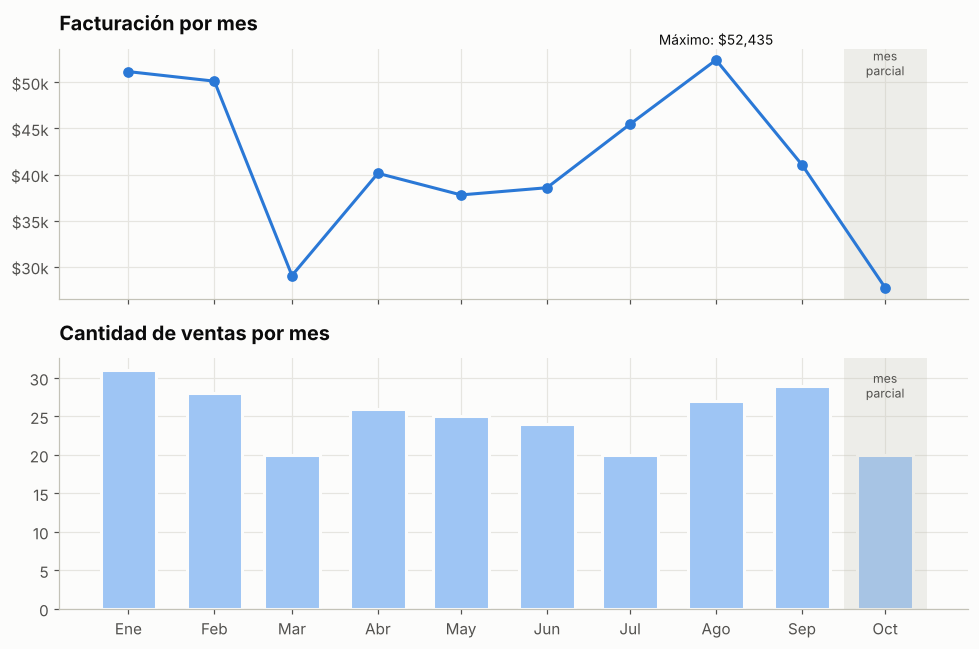

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax1.plot(monthly["month"], monthly["revenue"], color=BLUE, linewidth=2, marker="o", markersize=6)
ax1.yaxis.set_major_formatter(money)
ax1.set_title("Facturación por mes")
best = monthly.loc[monthly["revenue"].idxmax()]
ax1.annotate(f"Máximo: ${best['revenue']:,.0f}", (best["month"], best["revenue"]),
             xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9, color=INK)

ax2.bar(monthly["month"], monthly["sales_count"], width=20, color=BLUE_LIGHT,
        edgecolor="#fcfcfb", linewidth=2)
ax2.set_title("Cantidad de ventas por mes")
ax2.set_xticks(monthly["month"])
ax2.set_xticklabels([MONTHS[m.month - 1] for m in monthly["month"]])

if partial_month:
    for ax in (ax1, ax2):
        ax.axvspan(monthly["month"].iloc[-1] - pd.Timedelta(days=15),
                   monthly["month"].iloc[-1] + pd.Timedelta(days=15), color=GRAY, alpha=0.25, lw=0)
    ax1.text(monthly["month"].iloc[-1], ax1.get_ylim()[1], "mes\nparcial",
             ha="center", va="top", fontsize=8, color=INK_2)
    ax2.text(monthly["month"].iloc[-1], ax2.get_ylim()[1] * 0.95, "mes\nparcial",
             ha="center", va="top", fontsize=8, color=INK_2)

fig.tight_layout()
plt.show()

In [6]:
complete = monthly.iloc[:-1] if partial_month else monthly
print(f"Facturación mensual promedio (meses completos): ${complete['revenue'].mean():,.0f}")
best_month = complete.loc[complete["revenue"].idxmax(), "month"]
worst_month = complete.loc[complete["revenue"].idxmin(), "month"]
print(f"Mejor mes:  {MONTHS_LONG[best_month.month - 1]} (${complete['revenue'].max():,.0f})")
print(f"Peor mes:   {MONTHS_LONG[worst_month.month - 1]} (${complete['revenue'].min():,.0f})")
print(f"Ticket promedio por mes: entre ${complete['average_ticket'].min():,.0f} y ${complete['average_ticket'].max():,.0f}")

Facturación mensual promedio (meses completos): $42,872
Mejor mes:  agosto ($52,435)
Peor mes:   marzo ($29,050)
Ticket promedio por mes: entre $1,416 y $2,274


**Lectura.** La facturación no muestra una tendencia clara de crecimiento ni de caída: oscila alrededor de los $42.000 mensuales. Enero, febrero y agosto son los meses más fuertes, y marzo el más débil. Julio es un caso interesante: tuvo de las menores cantidades de ventas pero una facturación alta, porque el ticket promedio de ese mes fue mayor (se vendieron equipos más caros). El último mes está incompleto y no debe compararse con el resto.

## 3. Desempeño de los vendedores

Total vendido y comisión ganada por cada vendedor (`/reports/sellers`).

In [7]:
sellers = get_df("/reports/sellers")
sellers["share_%"] = (sellers["total_amount"] / sellers["total_amount"].sum() * 100).round(1)
sellers[["full_name_seller", "sales_count", "total_amount", "share_%", "commission_rate", "commission_earned"]]

,full_name_seller,sales_count,total_amount,share_%,commission_rate,commission_earned
0,Carla Moreno,43,80605.0,19.5,0.06,4836.30
1,Lucas Herrera,46,79325.0,19.2,0.04,3173.00
2,Paula Castro,46,76180.0,18.4,0.08,6094.40
3,Diego Ruiz,45,64420.0,15.6,0.07,4509.40
4,Ana Torres,36,56790.0,13.7,0.05,2839.50
5,Ramiro Ortiz,34,56265.0,13.6,0.05,2813.25


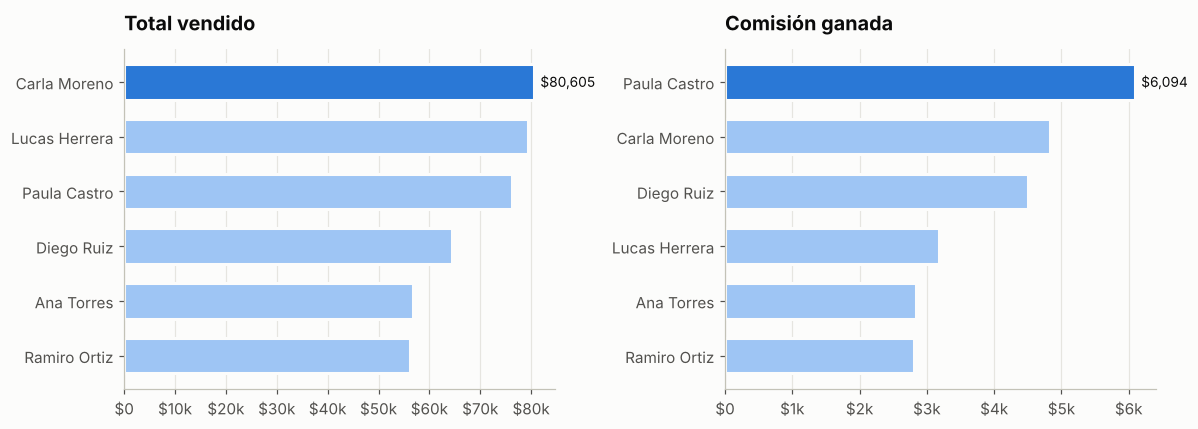

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

hbar(ax1, sellers["full_name_seller"], sellers["total_amount"], highlight=0, fmt="${:,.0f}")
ax1.xaxis.set_major_formatter(money)
ax1.set_title("Total vendido")

by_commission = sellers.sort_values("commission_earned", ascending=False)
hbar(ax2, by_commission["full_name_seller"], by_commission["commission_earned"], highlight=0, fmt="${:,.0f}")
ax2.xaxis.set_major_formatter(money)
ax2.set_title("Comisión ganada")

fig.tight_layout()
plt.show()

**Lectura.** Las ventas están bastante repartidas: los seis vendedores tienen entre el 13% y el 20% del total. Sin embargo, **el ranking de comisiones no coincide con el de ventas**: Paula Castro es tercera en facturación pero la que más comisión cobra, porque su tasa (8%) es la más alta. A la inversa, Lucas Herrera vende casi lo mismo que Carla Moreno, la primera, pero cobra un tercio menos que ella y cerca de la mitad que Paula Castro, porque su tasa es la más baja (4%). Esto sugiere revisar el esquema de comisiones para que premie el volumen vendido y no solo la tasa asignada.

## 4. Ventas por línea de producto

Facturación por línea (`/reports/sales-by-line`). La línea es la segunda palabra del nombre de la computadora.

In [9]:
lines = get_df("/reports/sales-by-line")
lines["share_%"] = (lines["revenue"] / lines["revenue"].sum() * 100).round(1)
lines["average_ticket"] = (lines["revenue"] / lines["sales_count"]).round(2)
lines

,sales_count,units_sold,line,revenue,share_%,average_ticket
0,65,87,Creator,122515.0,29.6,1884.85
1,56,70,Gamer,110560.0,26.7,1974.29
2,58,77,Office,77910.0,18.8,1343.28
3,38,45,Streamer,66720.0,16.1,1755.79
4,33,38,Home,35880.0,8.7,1087.27


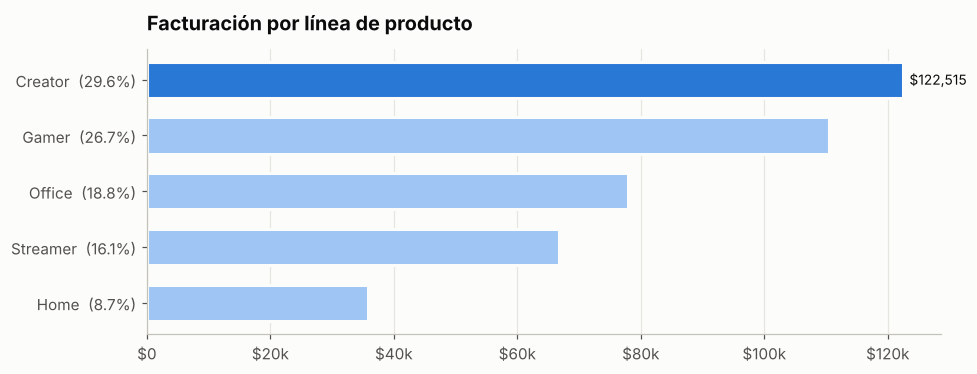

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.5))
hbar(ax, lines["line"], lines["revenue"], highlight=0, fmt="${:,.0f}")
ax.xaxis.set_major_formatter(money)
ax.set_title("Facturación por línea de producto")
ax.set_yticks(range(len(lines)))
ax.set_yticklabels([f"{l}  ({s}%)" for l, s in zip(lines["line"][::-1], lines["share_%"][::-1])])
fig.tight_layout()
plt.show()

**Lectura.** Las líneas con placa de video (**Creator, Gamer y Streamer**) concentran más del 70% de la facturación. Office registra incluso más ventas que Gamer, pero factura bastante menos porque su ticket es más bajo. Home es la línea más chica en ventas y en facturación.

## 5. Computadoras más vendidas

Top 10 por unidades vendidas (`/reports/top-computers`).

In [11]:
top_pcs = get_df("/reports/top-computers", limit=10)
top_pcs["unit_price"] = (top_pcs["total_amount"] / top_pcs["units_sold"]).round(2)
top_pcs[["id_computer", "name_computer", "units_sold", "unit_price", "total_amount"]]

,id_computer,name_computer,units_sold,unit_price,total_amount
0,pc-016,TechCore Creator 016,15,1450.0,21750.0
1,pc-022,TechCore Gamer 022,15,1355.0,20325.0
2,pc-020,TechCore Creator 020,14,1365.0,19110.0
3,pc-038,TechCore Gamer 038,12,2905.0,34860.0
4,pc-029,TechCore Streamer 029,11,1450.0,15950.0
5,pc-030,TechCore Office 030,11,1135.0,12485.0
6,pc-034,TechCore Creator 034,10,1800.0,18000.0
7,pc-028,TechCore Creator 028,10,1435.0,14350.0
8,pc-032,TechCore Office 032,10,1405.0,14050.0
9,pc-007,TechCore Office 007,10,1050.0,10500.0


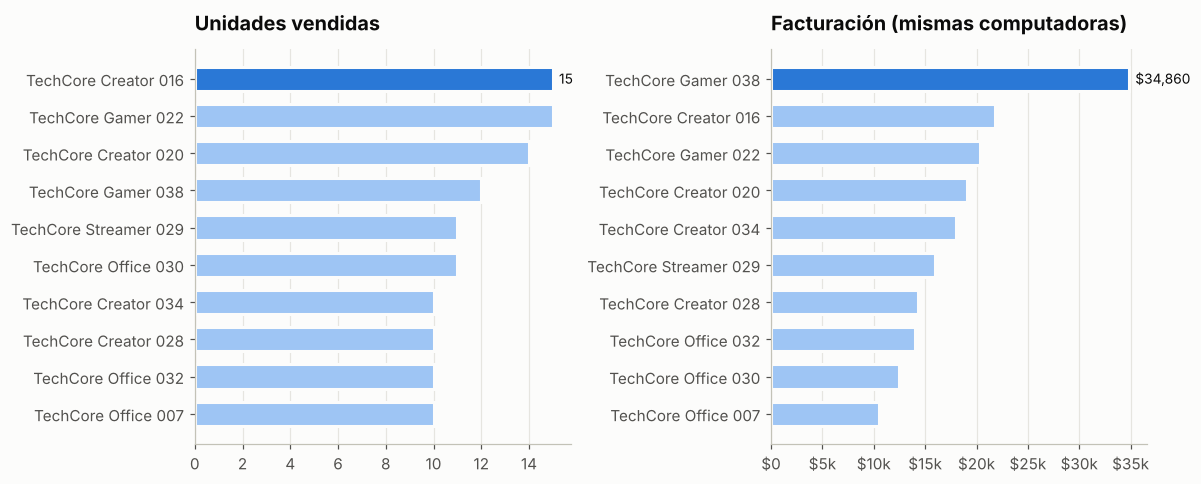

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

hbar(ax1, top_pcs["name_computer"], top_pcs["units_sold"], highlight=0)
ax1.set_title("Unidades vendidas")

by_amount = top_pcs.sort_values("total_amount", ascending=False)
hbar(ax2, by_amount["name_computer"], by_amount["total_amount"], highlight=0, fmt="${:,.0f}")
ax2.xaxis.set_major_formatter(money)
ax2.set_title("Facturación (mismas computadoras)")

fig.tight_layout()
plt.show()

**Lectura.** Los tres equipos más vendidos son de gama media (entre $1.350 y $1.450 cada uno). Pero el que más factura **no es el que más unidades vende**: la Gamer 038, con un precio cercano a $2.900, genera más ingresos que cualquier otra aunque vendió menos unidades. Conviene cuidar el stock de ambos grupos: los de alta rotación y los de alto valor.

## 6. Mejores clientes

Top 10 clientes por monto gastado (`/reports/top-clients`).

In [13]:
clients = get_df("/reports/top-clients", limit=10)
clients["share_%"] = (clients["total_spent"] / summary["total_revenue"] * 100).round(1)
clients

,full_name_client,purchases,units_bought,id_client,total_spent,average_ticket,share_%
0,Julieta Romero,11,13,cli-029,18805.0,1709.55,4.5
1,Benjamín Sánchez,7,10,cli-039,18515.0,2645.00,4.5
2,Tomás López,11,14,cli-009,17895.0,1626.82,4.3
3,Joaquín Ruiz,7,10,cli-037,15655.0,2236.43,3.8
4,Facundo Rodríguez,11,13,cli-031,15645.0,1422.27,3.8
5,Valentina López,9,12,cli-040,15490.0,1721.11,3.7
6,Santiago Ramírez,9,10,cli-027,14635.0,1626.11,3.5
7,Agustina Rodríguez,7,9,cli-022,13865.0,1980.71,3.4
8,Julieta Medina,6,11,cli-033,13040.0,2173.33,3.2
9,Martina Sánchez,7,9,cli-003,12705.0,1815.00,3.1


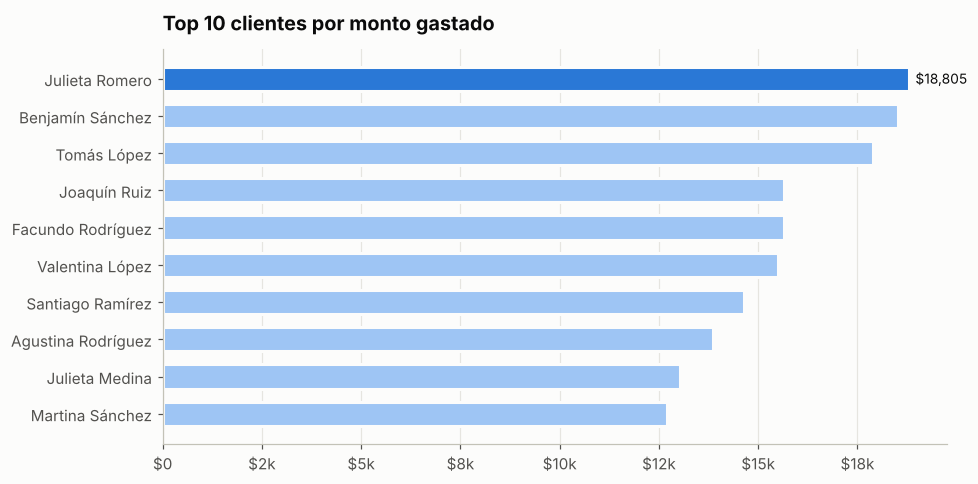

Los 10 mejores clientes representan el 37.8% de la facturación (26% de los clientes).


In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
hbar(ax, clients["full_name_client"], clients["total_spent"], highlight=0, fmt="${:,.0f}")
ax.xaxis.set_major_formatter(money)
ax.set_title("Top 10 clientes por monto gastado")
fig.tight_layout()
plt.show()

top10_share = clients["total_spent"].sum() / summary["total_revenue"] * 100
print(f"Los 10 mejores clientes representan el {top10_share:.1f}% de la facturación "
      f"({10 / summary['clients_count'] * 100:.0f}% de los clientes).")

**Lectura.** No hay un cliente que domine las ventas: el mejor aporta menos del 5% del total. Algunos llegan al top por **frecuencia** (muchas compras de ticket medio) y otros por **ticket alto** (menos compras pero más caras). Son dos perfiles distintos a la hora de pensar promociones o fidelización.

## 7. Unidades por venta

Cuántas ventas fueron de 1, 2 o 3 unidades (`/reports/quantity-distribution`).

In [15]:
quantity = get_df("/reports/quantity-distribution")
quantity["share_%"] = (quantity["sales_count"] / quantity["sales_count"].sum() * 100).round(1)
quantity

,sales_count,quantity,revenue,share_%
0,190,1,243135.0,76.0
1,53,2,139250.0,21.2
2,7,3,31200.0,2.8


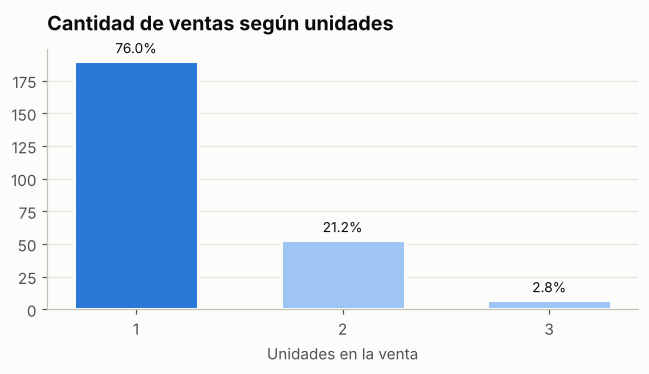

In [16]:
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(quantity["quantity"].astype(str), quantity["sales_count"], width=0.6,
              color=[BLUE] + [BLUE_LIGHT] * (len(quantity) - 1), edgecolor="#fcfcfb", linewidth=2)
ax.bar_label(bars, labels=[f"{s}%" for s in quantity["share_%"]], padding=3, fontsize=9, color=INK)
ax.set_xlabel("Unidades en la venta")
ax.set_title("Cantidad de ventas según unidades")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

**Lectura.** Tres de cada cuatro ventas son de una sola computadora: el cliente típico es individual. Las ventas de 2 o más unidades son pocas pero aportan alrededor del 40% de la facturación, por lo que una política de descuento por cantidad podría impulsarlas.

## 8. Catálogo por rango de precio

Cantidad de computadoras y stock disponible por rango de precio (`/reports/price-ranges`).

In [17]:
ranges = get_df("/reports/price-ranges")
ranges

,price_range,computers_count,stock,average_price
0,0-750,3,16,613.33
1,750-1000,4,16,833.75
2,1000-1500,26,155,1258.46
3,1500-2000,5,14,1659.00
4,2000-3000,2,6,2480.00
5,3000+,0,0,0.00


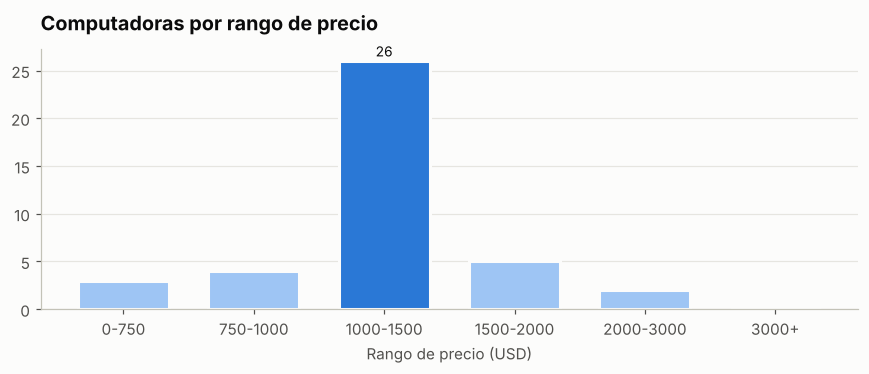

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.5))
peak = ranges["computers_count"].idxmax()
bars = ax.bar(ranges["price_range"], ranges["computers_count"], width=0.7,
              color=[BLUE if i == peak else BLUE_LIGHT for i in range(len(ranges))],
              edgecolor="#fcfcfb", linewidth=2)
label_bar(ax, bars[peak], str(ranges.loc[peak, "computers_count"]), horizontal=False)
ax.set_xlabel("Rango de precio (USD)")
ax.set_title("Computadoras por rango de precio")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

**Lectura.** El catálogo está muy concentrado en el rango **$1.000 – $1.500**: ahí está más del 60% de las computadoras y la mayor parte del stock. Los extremos (entrada por debajo de $750 y alta gama por encima de $2.000) tienen muy pocas opciones, lo que puede dejar afuera a clientes con presupuestos muy bajos o muy altos.

## 9. Inventario de componentes por categoría

Valor del inventario (precio × stock) y faltantes por categoría (`/reports/inventory-by-category`).

In [19]:
inventory = get_df("/reports/inventory-by-category")
inventory["value_share_%"] = (inventory["inventory_value"] / inventory["inventory_value"].sum() * 100).round(1)
inventory[["category", "components_count", "units_in_stock", "out_of_stock", "average_price",
           "inventory_value", "value_share_%"]]

,category,components_count,units_in_stock,out_of_stock,average_price,inventory_value,value_share_%
0,GPU,12,110,2,640.83,56770.0,40.4
1,CPU,12,128,1,338.75,43055.0,30.6
2,RAM,9,137,1,107.22,15200.0,10.8
3,SSD,8,91,1,106.25,8490.0,6.0
4,Motherboard,9,48,1,196.67,7985.0,5.7
5,Case,5,51,0,97.00,4545.0,3.2
6,PSU,5,53,1,124.00,4535.0,3.2


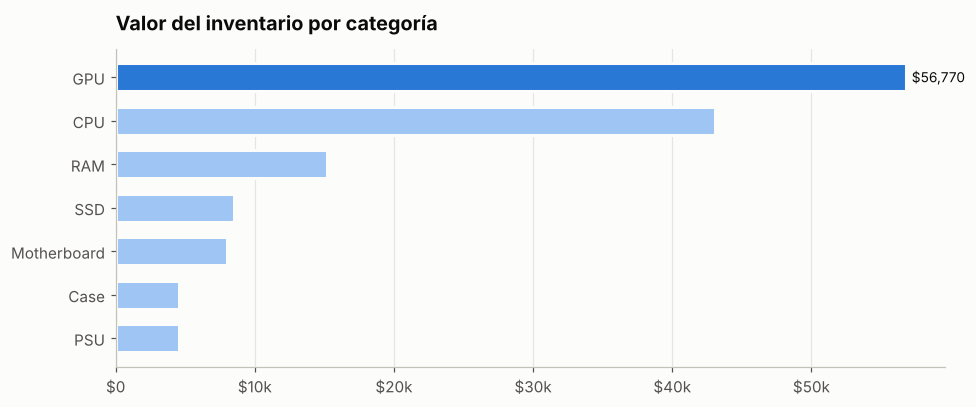

Valor total del inventario de componentes: $140,580
Componentes sin stock: 7 de 60


In [20]:
fig, ax = plt.subplots(figsize=(9, 3.8))
hbar(ax, inventory["category"], inventory["inventory_value"], highlight=0, fmt="${:,.0f}")
ax.xaxis.set_major_formatter(money)
ax.set_title("Valor del inventario por categoría")
fig.tight_layout()
plt.show()

print(f"Valor total del inventario de componentes: ${inventory['inventory_value'].sum():,.0f}")
print(f"Componentes sin stock: {inventory['out_of_stock'].sum()} de {inventory['components_count'].sum()}")

**Lectura.** Las **placas de video y los procesadores** concentran más del 70% del dinero inmovilizado en stock, aunque no son las categorías con más unidades (la RAM tiene más). Es donde más conviene ajustar las compras: un exceso de stock de GPU pesa mucho más que uno de gabinetes o fuentes.

## 10. Componentes más usados y riesgo de stock

Componentes que aparecen en más computadoras (`/reports/component-usage`), cruzados con su stock actual. Un componente muy usado y con poco stock frena el armado de varias computadoras a la vez.

In [21]:
LOW_STOCK = 3

usage = get_df("/reports/component-usage", limit=15)
usage["at_risk"] = usage["stock_component"] <= LOW_STOCK
usage[["id_component", "name_component", "category", "used_in_computers", "stock_component", "at_risk"]]

,id_component,name_component,category,used_in_computers,stock_component,at_risk
0,cmp-051,Corsair RM750e,PSU,13,10,False
1,cmp-059,Cooler Master Q300L,Case,10,12,False
2,cmp-006,Kingston NV2 1TB,SSD,9,25,False
3,cmp-040,WD Black SN850X 2TB,SSD,8,3,True
4,cmp-052,Corsair RM850x,PSU,8,10,False
5,cmp-057,Lian Li Lancool 216,Case,8,20,False
6,cmp-060,Fractal Design North,Case,8,2,True
7,cmp-035,Corsair Vengeance 32GB,RAM,7,5,False
8,cmp-037,Samsung 990 Pro 1TB,SSD,7,25,False
9,cmp-039,WD Black SN850X 1TB,SSD,7,0,True


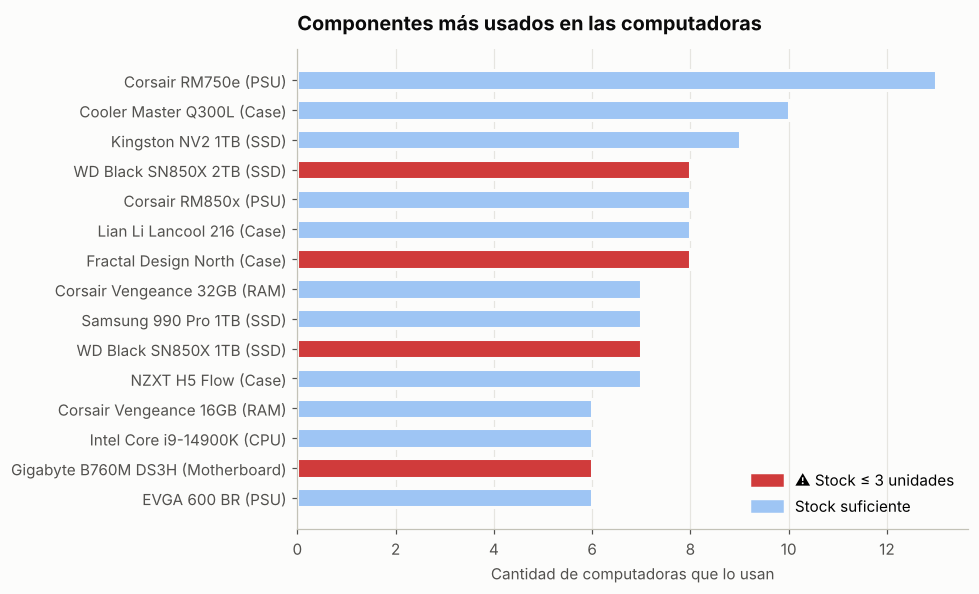

In [22]:
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [RED if risk else BLUE_LIGHT for risk in usage["at_risk"]]
hbar(ax, usage["name_component"] + " (" + usage["category"] + ")", usage["used_in_computers"], colors=colors)
ax.set_title("Componentes más usados en las computadoras")
ax.set_xlabel("Cantidad de computadoras que lo usan")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=RED, label=f"⚠ Stock ≤ {LOW_STOCK} unidades"),
                   plt.Rectangle((0, 0), 1, 1, color=BLUE_LIGHT, label="Stock suficiente")],
          loc="lower right", frameon=False)
fig.tight_layout()
plt.show()

In [23]:
low = get("/stock/low", threshold=LOW_STOCK)
low_components = pd.DataFrame(low["components"])
print(f"Componentes con stock ≤ {LOW_STOCK}: {len(low_components)}")
print(f"Computadoras con stock ≤ {LOW_STOCK}: {len(low['computers'])}")
low_components.sort_values("stock_component")[["id_component", "name_component", "stock_component"]]

Componentes con stock ≤ 3: 19
Computadoras con stock ≤ 3: 15


,id_component,name_component,stock_component
0,cmp-008,MSI Z790 Tomahawk,0
2,cmp-011,AMD Ryzen 7 7800X3D,0
6,cmp-022,RTX 4080 Super,0
7,cmp-023,RTX 4090,0
10,cmp-039,WD Black SN850X 1TB,0
9,cmp-029,Kingston Fury Beast 16GB,0
16,cmp-055,be quiet! Straight Power 12 1000W,0
5,cmp-019,RTX 4060 Ti,2
15,cmp-050,ASUS Prime H610M-E,2
4,cmp-016,Intel Core i5-14400F,2


**Lectura.** Los componentes más compartidos son los **genéricos** (fuentes, gabinetes y discos), que sirven para cualquier configuración. El riesgo está en los que aparecen en rojo: por ejemplo, el WD Black SN850X 1TB se usa en 7 computadoras y no tiene stock, así que ninguna de ellas puede armarse hasta reponerlo. Esta lista es la que conviene priorizar en la próxima compra.

## 11. Conclusiones

1. **Ventas estables, sin tendencia.** La facturación oscila alrededor de un promedio mensual sin crecer ni caer de forma sostenida.
2. **La gama media es el núcleo del negocio.** Concentra el catálogo, el stock y los modelos más vendidos. Los extremos de precio están poco cubiertos.
3. **Las líneas con GPU generan la mayor parte de los ingresos** (Creator, Gamer y Streamer), mientras que Office vende mucho pero a menor precio.
4. **El esquema de comisiones no está alineado con el volumen de ventas.** La tasa asignada pesa más que lo vendido en lo que cobra cada vendedor.
5. **Clientes recurrentes y compras individuales.** La mayoría de las ventas es de una unidad, y los clientes vuelven a comprar varias veces.
6. **El stock necesita atención en dos frentes:** el dinero inmovilizado en GPU y CPU, y los componentes compartidos con poco stock, que bloquean el armado de varias computadoras.

> Los datos analizados provienen de `seed.py` (generados con semilla fija), por lo que los patrones sirven para mostrar el análisis y no representan un negocio real. Como el notebook consulta la API en cada ejecución, al cargar datos reales los gráficos y los indicadores se recalculan solos; los textos de **Lectura** sí deberían revisarse.